ORIGINAL DATA
Kaggle train shape: (593994, 13)
Shared test shape: (20000, 13)

Target distribution:
loan_paid_back
1.0    0.79882
0.0    0.20118
Name: proportion, dtype: float64

Missing values in original training data:
0

Missing values in shared test:
0

TRAINING POOL
Original train rows: 593994
Shared test rows: 20000
Training pool rows: 573994
Training / test ID overlap: 0

FULL TRAINING MODE
Training pool size: 573994

MODEL FEATURES
Number of model features: 7
Sensitive attributes used as features: False

Features:
['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'loan_purpose', 'grade_subgrade']

TRAIN / VALIDATION SPLIT
Train: (459195, 7)
Validation: (114799, 7)
Train repayment rate: 0.7988196735591633
Validation repayment rate: 0.7988222893927648

Categorical variables:
['loan_purpose', 'grade_subgrade']

Numerical variables:
['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate']

TRAINING LIGHTGBM
Va

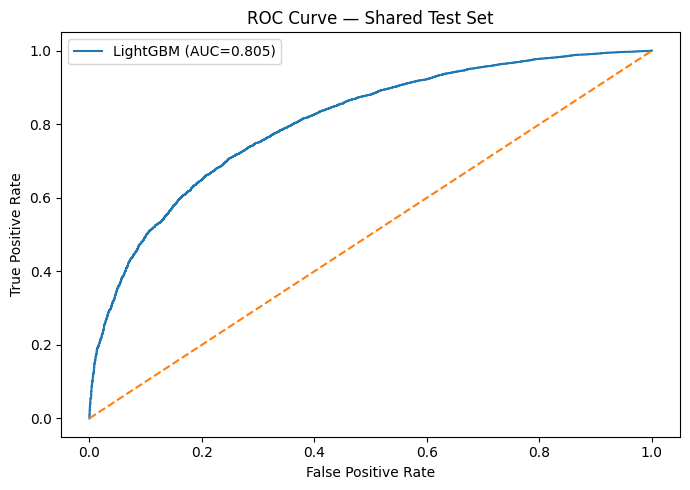

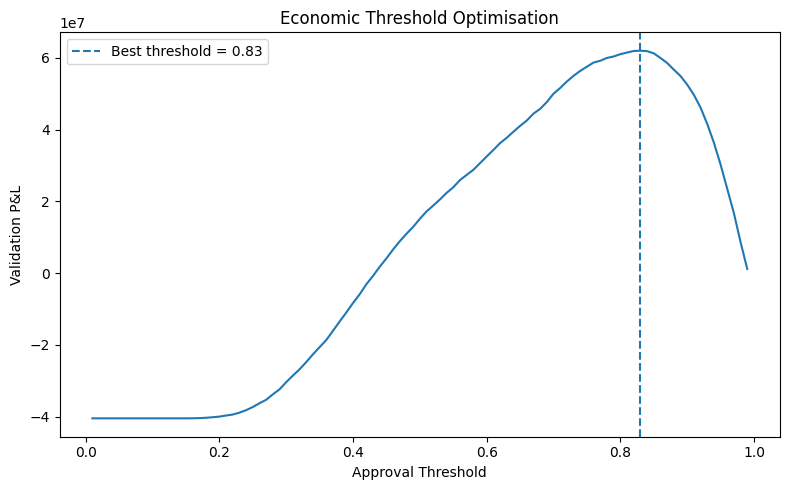


PERMUTATION IMPORTANCE
             Feature  Importance Mean  Importance Std
debt_to_income_ratio         0.183794        0.000888
        credit_score         0.089212        0.000760
         loan_amount         0.003730        0.000204
       annual_income         0.002565        0.000100
       interest_rate         0.001346        0.000091
      grade_subgrade         0.000586        0.000080
        loan_purpose         0.000581        0.000114


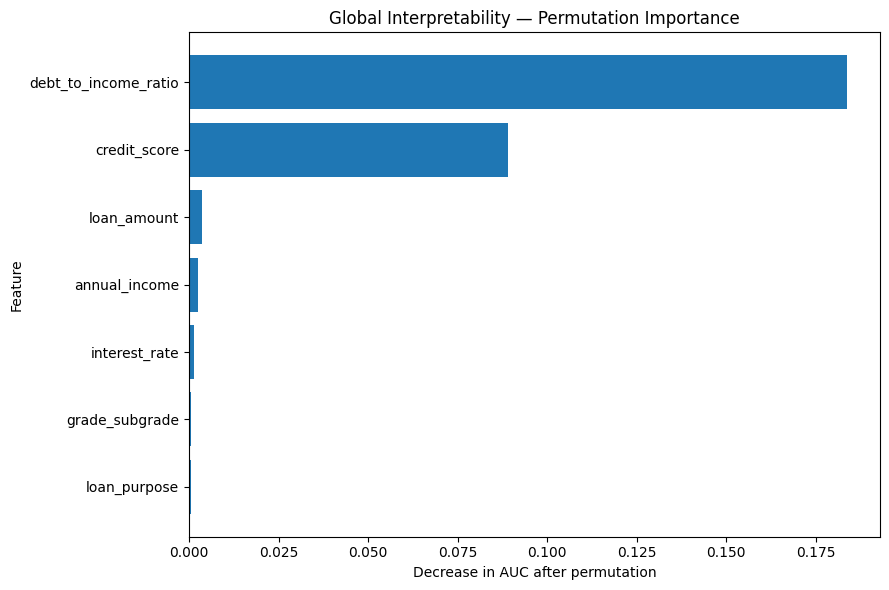


SHAP GLOBAL INTERPRETABILITY


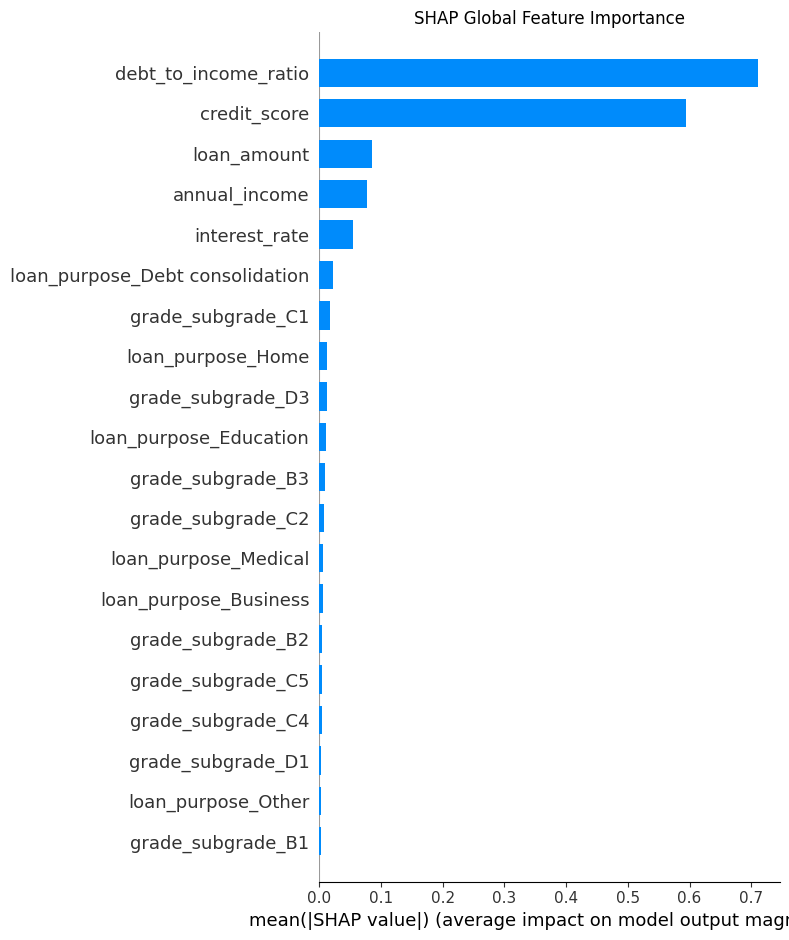

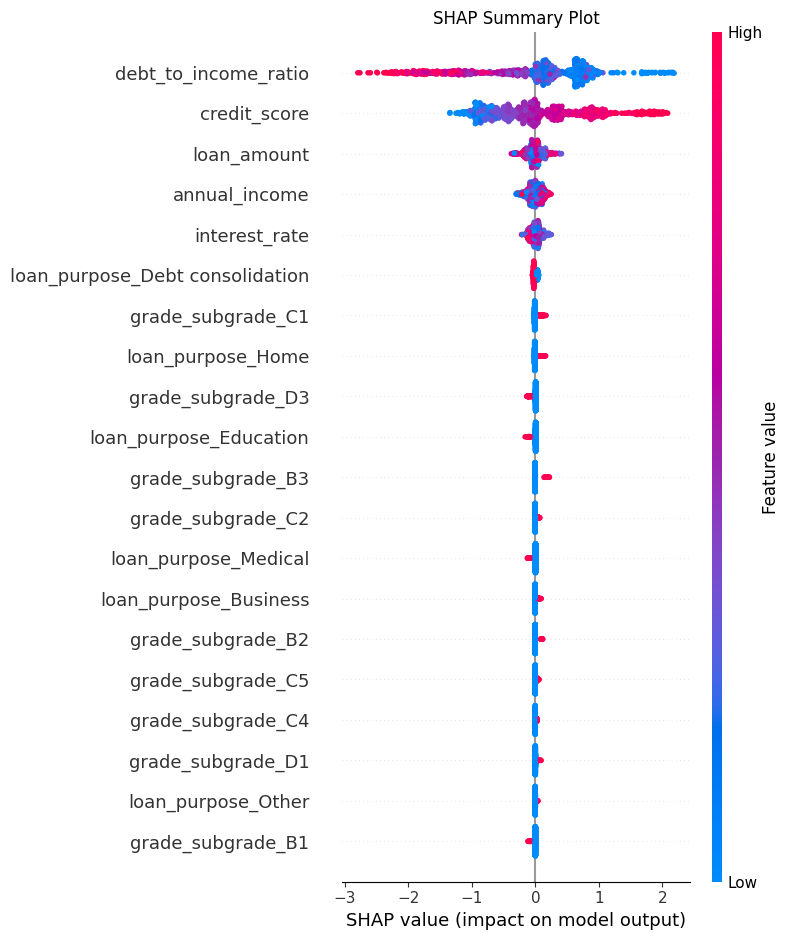


LOCAL EXPLANATION
Shared-test row: 0
Actual target: 1
Predicted repayment probability: 0.6585
Threshold: 0.83
Decision: REJECT


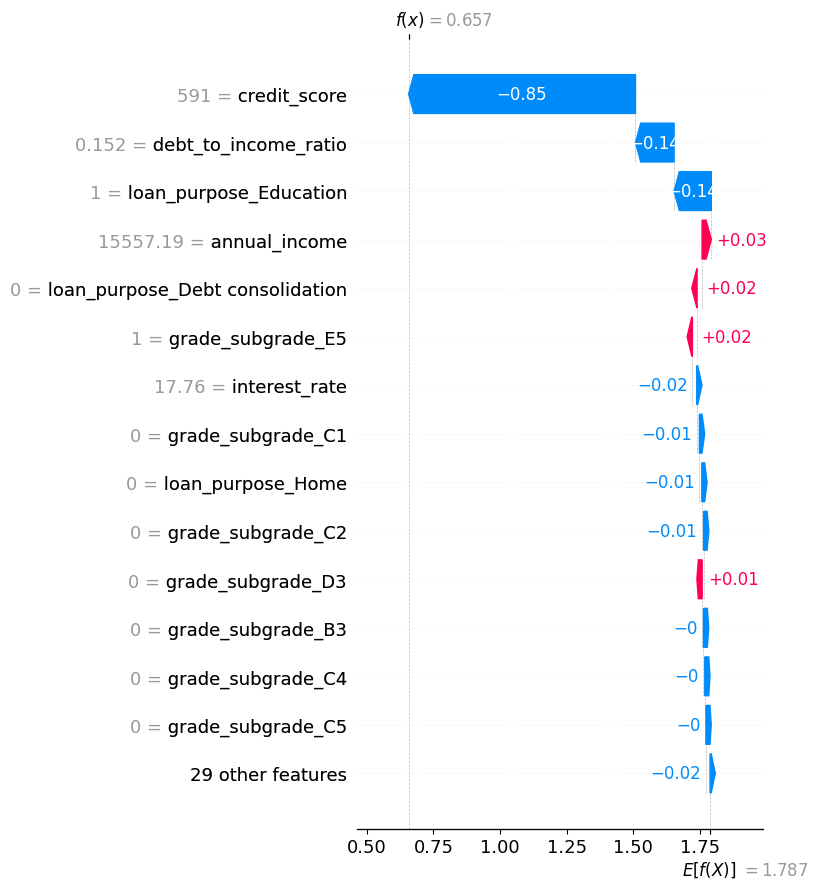


STABILITY ANALYSIS
Stability run — seed 1
Stability run — seed 10
Stability run — seed 42
Stability run — seed 100
Stability run — seed 2026

Individual runs:
 Seed      AUC  Brier Score  PCC / Accuracy          P&L  P&L per Applicant  Threshold  Approval Rate
    1 0.806077     0.125443        0.681591 6.307849e+07         549.468984       0.83       0.562087
   10 0.807575     0.125003        0.695294 6.249236e+07         544.363299       0.82       0.582967
   42 0.805240     0.125799        0.678638 6.199765e+07         540.053938       0.83       0.559273
  100 0.805433     0.125533        0.677279 6.282213e+07         547.235865       0.83       0.557165
 2026 0.809151     0.125073        0.680947 6.354204e+07         553.506881       0.83       0.559474

STABILITY SUMMARY
                           mean            std           min           max
AUC                8.066951e-01       0.001651  8.052398e-01  8.091510e-01
Brier Score        1.253704e-01       0.000331  1.250031e-0

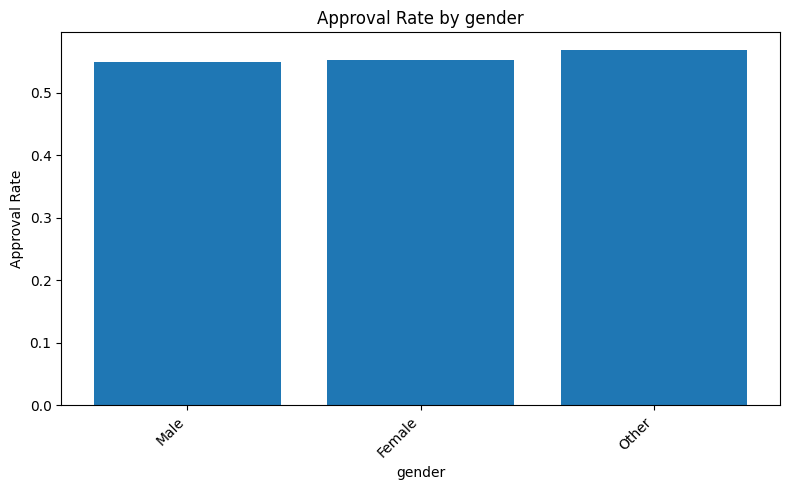

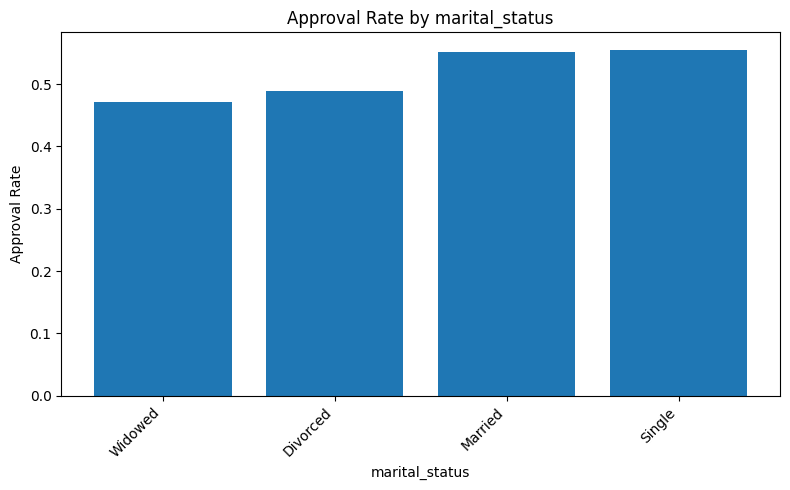

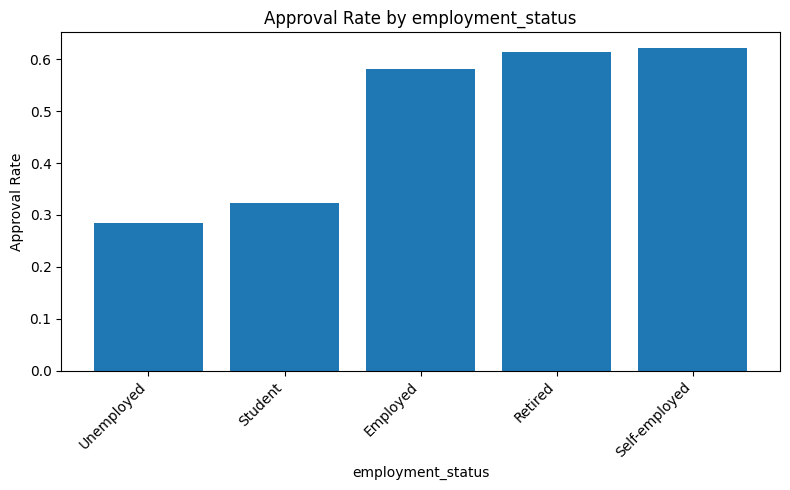

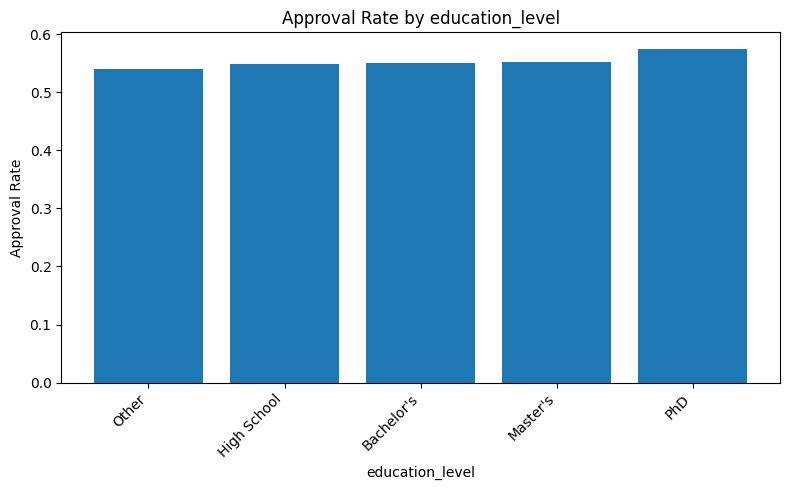


FINAL ML MODEL SUMMARY
   Model  Validation AUC  Test AUC  Test Brier Score  Test PCC / Accuracy  Economic Threshold     Test P&L  P&L per Applicant  Approval Rate
LightGBM         0.80524  0.805037          0.126408              0.67435                0.83 1.112939e+07         556.469323        0.55055

FILES SAVED
lightgbm_validation_metrics.csv
lightgbm_test_metrics.csv
lightgbm_threshold_analysis.csv
lightgbm_permutation_importance.csv
lightgbm_fairness_details.csv
lightgbm_fairness_summary.csv
lightgbm_final_summary.csv
lightgbm_test_predictions.csv
lightgbm_model.joblib
lightgbm_model_config.json
lightgbm_stability_runs.csv
lightgbm_stability_summary.csv


In [1]:
# ============================================================
# ML MODEL — LIGHTGBM
# ISAF PROJECT 2026-2027
#
# Covers:
# 1. Predictive Performance
# 2. Interpretability
# 3. Stability
# 4. Fairness
# ============================================================


# ============================================================
# 0. Imports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import json
import joblib

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    accuracy_score,
    confusion_matrix
)

from sklearn.inspection import permutation_importance

from lightgbm import LGBMClassifier

import shap


# ============================================================
# 1. Configuration
# ============================================================

TRAIN_PATH = "../data/train.csv"

# Shared final test set created by the group
EVAL_PATH = "../data/test_eval_20k.csv"

TARGET = "loan_paid_back"
ID_COL = "id"

SENSITIVE_COLS = [
    "gender",
    "marital_status",
    "employment_status",
    "education_level"
]

RANDOM_STATE = 42
VALID_SIZE = 0.20


# ------------------------------------------------------------
# FAST MODE
# ------------------------------------------------------------

# True:
# use a smaller training sample to check whether code runs
#
# False:
# use the full training pool for final results

FAST_MODE = False
SAMPLE_SIZE = 100_000


# ------------------------------------------------------------
# Sensitive attributes as predictors?
# ------------------------------------------------------------

# Recommended default:
# False = do not directly use sensitive attributes in the model.
#
# They are STILL retained separately for fairness analysis.
#
# Important:
# removing sensitive attributes does NOT automatically guarantee
# fairness because other variables may act as proxies.

INCLUDE_SENSITIVE_FEATURES = False


# ------------------------------------------------------------
# Stability
# ------------------------------------------------------------

RUN_STABILITY_ANALYSIS = True

STABILITY_SEEDS = [
    1,
    10,
    42,
    100,
    2026
]


# ------------------------------------------------------------
# SHAP
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE = 1000

# Which shared-test observation to explain locally
LOCAL_EXPLANATION_ROW = 0


# ============================================================
# 2. Load data
# ============================================================

train_full = pd.read_csv(TRAIN_PATH)
eval_df = pd.read_csv(EVAL_PATH)

print("========================================")
print("ORIGINAL DATA")
print("========================================")

print("Kaggle train shape:", train_full.shape)
print("Shared test shape:", eval_df.shape)

print("\nTarget distribution:")
print(train_full[TARGET].value_counts(normalize=True))


# ============================================================
# 3. Basic data checks
# ============================================================

required_columns = (
    [ID_COL, TARGET, "loan_amount", "interest_rate"]
    + SENSITIVE_COLS
)

for col in required_columns:

    assert col in train_full.columns, \
        f"Missing column in train.csv: {col}"

    assert col in eval_df.columns, \
        f"Missing column in test_eval_20k.csv: {col}"


print("\nMissing values in original training data:")
print(train_full.isna().sum().sum())

print("\nMissing values in shared test:")
print(eval_df.isna().sum().sum())


# ============================================================
# 4. Construct training pool
# ============================================================

# IMPORTANT:
# test_eval_20k.csv was taken from Kaggle train.csv.
#
# We MUST remove these rows before doing ANY:
# - training
# - validation
# - hyperparameter selection
# - threshold optimisation
#
# Otherwise there is test leakage.


training_pool = train_full[
    ~train_full[ID_COL].isin(eval_df[ID_COL])
].copy()


print("\n========================================")
print("TRAINING POOL")
print("========================================")

print("Original train rows:", len(train_full))
print("Shared test rows:", len(eval_df))
print("Training pool rows:", len(training_pool))


# ------------------------------------------------------------
# Leakage safety check
# ------------------------------------------------------------

overlap = training_pool[ID_COL].isin(
    eval_df[ID_COL]
).sum()

print("Training / test ID overlap:", overlap)

assert overlap == 0, \
    "DATA LEAKAGE: shared test rows are still in training data."


# Check that shared-test IDs actually came from train.csv

missing_eval_ids = (
    ~eval_df[ID_COL].isin(train_full[ID_COL])
).sum()

assert missing_eval_ids == 0, \
    "Some shared-test IDs are not present in original train.csv."


# ============================================================
# 5. Optional FAST MODE
# ============================================================

if FAST_MODE:

    sampled_idx, _ = train_test_split(
        training_pool.index,
        train_size=min(
            SAMPLE_SIZE,
            len(training_pool)
        ),
        stratify=training_pool[TARGET],
        random_state=RANDOM_STATE
    )

    training_pool = training_pool.loc[
        sampled_idx
    ].copy()

    print("\n========================================")
    print("FAST MODE ON")
    print("========================================")

    print(
        "Training pool reduced to:",
        len(training_pool)
    )

else:

    print("\n========================================")
    print("FULL TRAINING MODE")
    print("========================================")

    print(
        "Training pool size:",
        len(training_pool)
    )


# ============================================================
# 6. Define model features
# ============================================================

if INCLUDE_SENSITIVE_FEATURES:

    FEATURE_COLS = [
        col
        for col in training_pool.columns
        if col not in [
            TARGET,
            ID_COL
        ]
    ]

else:

    FEATURE_COLS = [
        col
        for col in training_pool.columns
        if col not in (
            [TARGET, ID_COL]
            + SENSITIVE_COLS
        )
    ]


print("\n========================================")
print("MODEL FEATURES")
print("========================================")

print(
    "Number of model features:",
    len(FEATURE_COLS)
)

print(
    "Sensitive attributes used as features:",
    INCLUDE_SENSITIVE_FEATURES
)

print("\nFeatures:")
print(FEATURE_COLS)


# ============================================================
# 7. Create X / y
# ============================================================

X = training_pool[
    FEATURE_COLS
].copy()

y = training_pool[
    TARGET
].astype(int).copy()


# Final shared test

X_eval = eval_df[
    FEATURE_COLS
].copy()

y_eval = eval_df[
    TARGET
].astype(int).copy()


# ============================================================
# 8. Train / Validation split
# ============================================================

train_idx, valid_idx = train_test_split(
    training_pool.index,
    test_size=VALID_SIZE,
    stratify=training_pool[TARGET],
    random_state=RANDOM_STATE
)


X_train = X.loc[
    train_idx
].copy()

X_valid = X.loc[
    valid_idx
].copy()

y_train = y.loc[
    train_idx
].copy()

y_valid = y.loc[
    valid_idx
].copy()


# Original validation rows are retained because
# loan_amount and interest_rate are needed for P&L.

valid_df = training_pool.loc[
    valid_idx
].copy()


print("\n========================================")
print("TRAIN / VALIDATION SPLIT")
print("========================================")

print("Train:", X_train.shape)
print("Validation:", X_valid.shape)

print(
    "Train repayment rate:",
    y_train.mean()
)

print(
    "Validation repayment rate:",
    y_valid.mean()
)


# ============================================================
# 9. Detect variable types
# ============================================================

categorical_cols = X_train.select_dtypes(
    include=[
        "object",
        "category"
    ]
).columns.tolist()


numerical_cols = [
    col
    for col in FEATURE_COLS
    if col not in categorical_cols
]


print("\nCategorical variables:")
print(categorical_cols)

print("\nNumerical variables:")
print(numerical_cols)


# ============================================================
# 10. Model factory
# ============================================================

def build_lightgbm_pipeline(random_state=42):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_cols
            ),
            (
                "numerical",
                "passthrough",
                numerical_cols
            )
        ]
    )


    model = LGBMClassifier(

        objective="binary",

        n_estimators=300,

        learning_rate=0.05,

        num_leaves=31,

        max_depth=-1,

        subsample=0.8,

        colsample_bytree=0.8,

        reg_alpha=1.0,

        reg_lambda=5.0,

        random_state=random_state,

        n_jobs=-1,

        verbosity=-1
    )


    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    return pipeline


# ============================================================
# 11. Economic P&L
# ============================================================

def profit_vector(
    y_true,
    prob_repaid,
    loan_amount,
    interest_rate,
    threshold
):

    y_true = np.asarray(y_true)

    prob_repaid = np.asarray(
        prob_repaid
    )

    loan_amount = np.asarray(
        loan_amount
    )

    interest_rate = np.asarray(
        interest_rate
    )


    # Model approves when predicted probability of repayment
    # is greater than or equal to the threshold.

    approved = (
        prob_repaid >= threshold
    )

    repaid = (
        y_true == 1
    )

    defaulted = (
        y_true == 0
    )


    profit = np.where(

        approved & repaid,

        # Approved and repaid
        loan_amount
        * interest_rate
        / 100,

        np.where(

            approved & defaulted,

            # Approved and defaulted:
            # bank loses 60% of principal
            -loan_amount * 0.60,

            # Rejected
            0
        )
    )

    return profit


def calculate_pnl(
    y_true,
    prob_repaid,
    loan_amount,
    interest_rate,
    threshold
):

    profits = profit_vector(
        y_true=y_true,
        prob_repaid=prob_repaid,
        loan_amount=loan_amount,
        interest_rate=interest_rate,
        threshold=threshold
    )

    return profits.sum()


# ============================================================
# 12. Find economic approval threshold
# ============================================================

def find_best_threshold(
    y_true,
    prob_repaid,
    loan_amount,
    interest_rate
):

    thresholds = np.arange(
        0.01,
        1.00,
        0.01
    )

    rows = []


    for threshold in thresholds:

        pnl = calculate_pnl(
            y_true=y_true,
            prob_repaid=prob_repaid,
            loan_amount=loan_amount,
            interest_rate=interest_rate,
            threshold=threshold
        )


        approval_rate = (
            np.asarray(prob_repaid)
            >= threshold
        ).mean()


        rows.append(
            {
                "Threshold": threshold,
                "P&L": pnl,
                "P&L per Applicant":
                    pnl / len(y_true),
                "Approval Rate":
                    approval_rate
            }
        )


    table = pd.DataFrame(
        rows
    )


    best_idx = table[
        "P&L"
    ].idxmax()


    best_threshold = float(
        table.loc[
            best_idx,
            "Threshold"
        ]
    )


    return (
        best_threshold,
        table
    )


# ============================================================
# 13. Predictive-performance function
# ============================================================

def evaluate_predictions(
    y_true,
    probabilities,
    loan_amount,
    interest_rate,
    threshold
):

    y_true = np.asarray(
        y_true
    )

    probabilities = np.asarray(
        probabilities
    )


    decisions = (
        probabilities
        >= threshold
    ).astype(int)


    # ----------------------------
    # Statistical performance
    # ----------------------------

    auc = roc_auc_score(
        y_true,
        probabilities
    )


    brier = brier_score_loss(
        y_true,
        probabilities
    )


    accuracy = accuracy_score(
        y_true,
        decisions
    )


    # ----------------------------
    # Economic performance
    # ----------------------------

    pnl = calculate_pnl(
        y_true=y_true,
        prob_repaid=probabilities,
        loan_amount=loan_amount,
        interest_rate=interest_rate,
        threshold=threshold
    )


    approval_rate = (
        decisions.mean()
    )


    if decisions.sum() > 0:

        default_rate_approved = (
            y_true[
                decisions == 1
            ] == 0
        ).mean()

    else:

        default_rate_approved = np.nan


    return {
        "AUC": auc,

        "Brier Score": brier,

        "PCC / Accuracy": accuracy,

        "P&L": pnl,

        "P&L per Applicant":
            pnl / len(y_true),

        "Approval Rate":
            approval_rate,

        "Default Rate Among Approved":
            default_rate_approved
    }


# ============================================================
# 14. Train main LightGBM
# ============================================================

print("\n========================================")
print("TRAINING LIGHTGBM")
print("========================================")


lgbm_pipeline = build_lightgbm_pipeline(
    random_state=RANDOM_STATE
)


lgbm_pipeline.fit(
    X_train,
    y_train
)


# ============================================================
# 15. Validation predictions
# ============================================================

valid_pred = (
    lgbm_pipeline
    .predict_proba(
        X_valid
    )[:, 1]
)


validation_auc = roc_auc_score(
    y_valid,
    valid_pred
)


print(
    "Validation AUC:",
    round(validation_auc, 6)
)


# ============================================================
# 16. Select threshold ONLY on validation data
# ============================================================

best_threshold, threshold_table = (
    find_best_threshold(

        y_true=y_valid,

        prob_repaid=valid_pred,

        loan_amount=
            valid_df["loan_amount"],

        interest_rate=
            valid_df["interest_rate"]
    )
)


print("\n========================================")
print("ECONOMIC THRESHOLD")
print("========================================")

print(
    "Best validation threshold:",
    round(best_threshold, 2)
)


best_validation_pnl = (
    threshold_table[
        "P&L"
    ].max()
)


print(
    "Best validation P&L:",
    f"{best_validation_pnl:,.2f}"
)


# ============================================================
# 17. Validation performance
# ============================================================

validation_metrics = evaluate_predictions(

    y_true=y_valid,

    probabilities=valid_pred,

    loan_amount=
        valid_df["loan_amount"],

    interest_rate=
        valid_df["interest_rate"],

    threshold=best_threshold
)


validation_metrics_df = pd.DataFrame(
    [validation_metrics]
)


validation_metrics_df.insert(
    0,
    "Dataset",
    "Validation"
)


print("\n========================================")
print("VALIDATION PERFORMANCE")
print("========================================")

print(
    validation_metrics_df
    .to_string(index=False)
)


# ============================================================
# 18. FINAL evaluation on shared 20k test
# ============================================================

# IMPORTANT:
#
# No:
# - threshold optimisation
# - hyperparameter tuning
# - feature selection
#
# is done using this dataset.


eval_pred = (
    lgbm_pipeline
    .predict_proba(
        X_eval
    )[:, 1]
)


test_metrics = evaluate_predictions(

    y_true=y_eval,

    probabilities=eval_pred,

    loan_amount=
        eval_df["loan_amount"],

    interest_rate=
        eval_df["interest_rate"],

    threshold=best_threshold
)


test_metrics_df = pd.DataFrame(
    [test_metrics]
)


test_metrics_df.insert(
    0,
    "Dataset",
    "Shared Test 20k"
)


print("\n========================================")
print("FINAL SHARED-TEST PERFORMANCE")
print("========================================")

print(
    test_metrics_df
    .to_string(index=False)
)


# ============================================================
# 19. Confusion matrix
# ============================================================

eval_decision = (
    eval_pred
    >= best_threshold
).astype(int)


tn, fp, fn, tp = confusion_matrix(
    y_eval,
    eval_decision,
    labels=[0, 1]
).ravel()


confusion_df = pd.DataFrame(
    {
        "Metric": [
            "True Negative",
            "False Positive",
            "False Negative",
            "True Positive"
        ],

        "Value": [
            tn,
            fp,
            fn,
            tp
        ]
    }
)


print("\n========================================")
print("CONFUSION MATRIX COUNTS")
print("========================================")

print(
    confusion_df
    .to_string(index=False)
)


# ============================================================
# 20. ROC curve
# ============================================================

fpr, tpr, _ = roc_curve(
    y_eval,
    eval_pred
)


plt.figure(
    figsize=(7, 5)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"LightGBM "
        f"(AUC={test_metrics['AUC']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve — Shared Test Set"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 21. P&L versus threshold
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    threshold_table["Threshold"],
    threshold_table["P&L"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Best threshold "
        f"= {best_threshold:.2f}"
    )
)

plt.xlabel(
    "Approval Threshold"
)

plt.ylabel(
    "Validation P&L"
)

plt.title(
    "Economic Threshold Optimisation"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 22. INTERPRETABILITY — Permutation Importance
# ============================================================

# Global interpretability:
#
# Each original feature is randomly permuted.
# We measure how much validation AUC decreases.
#
# Larger decrease = more important feature.


print("\n========================================")
print("PERMUTATION IMPORTANCE")
print("========================================")


perm_result = permutation_importance(

    lgbm_pipeline,

    X_valid,

    y_valid,

    scoring="roc_auc",

    n_repeats=5,

    random_state=
        RANDOM_STATE,

    n_jobs=-1
)


permutation_df = pd.DataFrame(
    {
        "Feature":
            X_valid.columns,

        "Importance Mean":
            perm_result.importances_mean,

        "Importance Std":
            perm_result.importances_std
    }
)


permutation_df = (
    permutation_df
    .sort_values(
        "Importance Mean",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    permutation_df
    .head(20)
    .to_string(index=False)
)


top_perm = (
    permutation_df
    .head(15)
    .sort_values(
        "Importance Mean"
    )
)


plt.figure(
    figsize=(9, 6)
)

plt.barh(
    top_perm["Feature"],
    top_perm["Importance Mean"]
)

plt.xlabel(
    "Decrease in AUC after permutation"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Global Interpretability — Permutation Importance"
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. INTERPRETABILITY — SHAP preparation
# ============================================================

preprocessor = (
    lgbm_pipeline
    .named_steps[
        "preprocessing"
    ]
)

fitted_model = (
    lgbm_pipeline
    .named_steps[
        "model"
    ]
)


# Take a manageable sample for SHAP

X_shap_original = X_valid.sample(

    n=min(
        SHAP_SAMPLE_SIZE,
        len(X_valid)
    ),

    random_state=
        RANDOM_STATE
)


X_shap_transformed = (
    preprocessor
    .transform(
        X_shap_original
    )
)


# Convert sparse matrix to dense only for
# the small SHAP sample.

if hasattr(
    X_shap_transformed,
    "toarray"
):

    X_shap_dense = (
        X_shap_transformed
        .toarray()
    )

else:

    X_shap_dense = (
        np.asarray(
            X_shap_transformed
        )
    )


encoded_feature_names = (
    preprocessor
    .get_feature_names_out()
)


# Make names cleaner

encoded_feature_names = [
    name.replace(
        "categorical__",
        ""
    ).replace(
        "numerical__",
        ""
    )
    for name
    in encoded_feature_names
]


# ============================================================
# 24. INTERPRETABILITY — SHAP global
# ============================================================

explainer = shap.TreeExplainer(
    fitted_model
)


raw_shap_values = (
    explainer
    .shap_values(
        X_shap_dense
    )
)


# Different SHAP versions return slightly
# different structures for binary classifiers.

if isinstance(
    raw_shap_values,
    list
):

    if len(
        raw_shap_values
    ) == 2:

        shap_values = (
            raw_shap_values[1]
        )

    else:

        shap_values = (
            raw_shap_values[0]
        )

else:

    shap_values = np.asarray(
        raw_shap_values
    )

    if (
        shap_values.ndim == 3
        and
        shap_values.shape[2] == 2
    ):

        shap_values = (
            shap_values[:, :, 1]
        )


print("\n========================================")
print("SHAP GLOBAL INTERPRETABILITY")
print("========================================")


# SHAP importance bar chart

shap.summary_plot(

    shap_values,

    X_shap_dense,

    feature_names=
        encoded_feature_names,

    plot_type="bar",

    max_display=20,

    show=False
)

plt.title(
    "SHAP Global Feature Importance"
)

plt.tight_layout()

plt.show()


# SHAP beeswarm:
# direction + magnitude of feature effects

shap.summary_plot(

    shap_values,

    X_shap_dense,

    feature_names=
        encoded_feature_names,

    max_display=20,

    show=False
)

plt.title(
    "SHAP Summary Plot"
)

plt.tight_layout()

plt.show()


# ============================================================
# 25. INTERPRETABILITY — Local SHAP explanation
# ============================================================

local_X_original = X_eval.iloc[
    [
        LOCAL_EXPLANATION_ROW
    ]
]


local_transformed = (
    preprocessor
    .transform(
        local_X_original
    )
)


if hasattr(
    local_transformed,
    "toarray"
):

    local_dense = (
        local_transformed
        .toarray()
    )

else:

    local_dense = (
        np.asarray(
            local_transformed
        )
    )


local_raw_shap = (
    explainer
    .shap_values(
        local_dense
    )
)


if isinstance(
    local_raw_shap,
    list
):

    if len(local_raw_shap) == 2:

        local_shap = (
            local_raw_shap[1]
        )

    else:

        local_shap = (
            local_raw_shap[0]
        )

else:

    local_shap = np.asarray(
        local_raw_shap
    )

    if (
        local_shap.ndim == 3
        and
        local_shap.shape[2] == 2
    ):

        local_shap = (
            local_shap[:, :, 1]
        )


expected_value = (
    explainer.expected_value
)


if isinstance(
    expected_value,
    (
        list,
        np.ndarray
    )
):

    expected_array = np.asarray(
        expected_value
    ).flatten()

    if len(expected_array) > 1:

        base_value = float(
            expected_array[-1]
        )

    else:

        base_value = float(
            expected_array[0]
        )

else:

    base_value = float(
        expected_value
    )


local_explanation = shap.Explanation(

    values=
        local_shap[0],

    base_values=
        base_value,

    data=
        local_dense[0],

    feature_names=
        encoded_feature_names
)


local_probability = float(
    eval_pred[
        LOCAL_EXPLANATION_ROW
    ]
)


local_decision = (
    "APPROVE"
    if local_probability
    >= best_threshold
    else "REJECT"
)


print("\n========================================")
print("LOCAL EXPLANATION")
print("========================================")

print(
    "Shared-test row:",
    LOCAL_EXPLANATION_ROW
)

print(
    "Actual target:",
    y_eval.iloc[
        LOCAL_EXPLANATION_ROW
    ]
)

print(
    "Predicted repayment probability:",
    round(
        local_probability,
        4
    )
)

print(
    "Threshold:",
    round(
        best_threshold,
        2
    )
)

print(
    "Decision:",
    local_decision
)


shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.show()


# ============================================================
# 26. STABILITY ANALYSIS
# ============================================================

# Stability definition used here:
#
# Retrain LightGBM using several different
# random train/validation splits.
#
# A stable model should show:
#
# - small AUC standard deviation
# - small Brier-score standard deviation
# - small P&L variability
# - reasonably stable economic threshold
# - reasonably stable approval rate
#
# IMPORTANT:
# Stability is evaluated INSIDE the training pool.
# Shared test is not used to select a seed.


def run_stability_analysis(
    data,
    feature_cols,
    seeds
):

    rows = []


    for seed in seeds:

        print(
            f"Stability run — seed {seed}"
        )


        tr_idx, va_idx = train_test_split(

            data.index,

            test_size=
                VALID_SIZE,

            stratify=
                data[TARGET],

            random_state=
                seed
        )


        X_tr = data.loc[
            tr_idx,
            feature_cols
        ]

        y_tr = data.loc[
            tr_idx,
            TARGET
        ].astype(int)


        X_va = data.loc[
            va_idx,
            feature_cols
        ]

        y_va = data.loc[
            va_idx,
            TARGET
        ].astype(int)


        va_original = data.loc[
            va_idx
        ]


        pipeline = (
            build_lightgbm_pipeline(
                random_state=seed
            )
        )


        pipeline.fit(
            X_tr,
            y_tr
        )


        pred = (
            pipeline
            .predict_proba(
                X_va
            )[:, 1]
        )


        threshold, _ = (
            find_best_threshold(

                y_true=
                    y_va,

                prob_repaid=
                    pred,

                loan_amount=
                    va_original[
                        "loan_amount"
                    ],

                interest_rate=
                    va_original[
                        "interest_rate"
                    ]
            )
        )


        metrics = evaluate_predictions(

            y_true=
                y_va,

            probabilities=
                pred,

            loan_amount=
                va_original[
                    "loan_amount"
                ],

            interest_rate=
                va_original[
                    "interest_rate"
                ],

            threshold=
                threshold
        )


        rows.append(
            {
                "Seed":
                    seed,

                "AUC":
                    metrics["AUC"],

                "Brier Score":
                    metrics[
                        "Brier Score"
                    ],

                "PCC / Accuracy":
                    metrics[
                        "PCC / Accuracy"
                    ],

                "P&L":
                    metrics["P&L"],

                "P&L per Applicant":
                    metrics[
                        "P&L per Applicant"
                    ],

                "Threshold":
                    threshold,

                "Approval Rate":
                    metrics[
                        "Approval Rate"
                    ]
            }
        )


    return pd.DataFrame(
        rows
    )


if RUN_STABILITY_ANALYSIS:

    print("\n========================================")
    print("STABILITY ANALYSIS")
    print("========================================")


    stability_results = (
        run_stability_analysis(

            data=
                training_pool,

            feature_cols=
                FEATURE_COLS,

            seeds=
                STABILITY_SEEDS
        )
    )


    print("\nIndividual runs:")

    print(
        stability_results
        .to_string(index=False)
    )


    stability_summary = (
        stability_results[
            [
                "AUC",
                "Brier Score",
                "PCC / Accuracy",
                "P&L",
                "P&L per Applicant",
                "Threshold",
                "Approval Rate"
            ]
        ]
        .agg(
            [
                "mean",
                "std",
                "min",
                "max"
            ]
        )
        .T
    )


    print("\n========================================")
    print("STABILITY SUMMARY")
    print("========================================")

    print(
        stability_summary
        .to_string()
    )


# ============================================================
# 27. FAIRNESS — group-level metrics
# ============================================================

# Target:
#
# 1 = repaid
# 0 = default
#
# Decision:
#
# 1 = approved
# 0 = rejected
#
# Therefore:
#
# TPR =
# proportion of genuinely repaying customers
# who are approved.
#
# FPR =
# proportion of genuinely defaulting customers
# who are nevertheless approved.


def fairness_by_group(
    df,
    y_true,
    probabilities,
    threshold,
    sensitive_col
):

    temp = pd.DataFrame(
        {
            "Group":
                df[
                    sensitive_col
                ].astype(str).values,

            "y_true":
                np.asarray(
                    y_true
                ),

            "probability":
                np.asarray(
                    probabilities
                )
        }
    )


    temp[
        "approved"
    ] = (
        temp[
            "probability"
        ]
        >= threshold
    ).astype(int)


    rows = []


    for group_name, group in (
        temp.groupby(
            "Group"
        )
    ):

        y_group = (
            group[
                "y_true"
            ].values
        )

        decision_group = (
            group[
                "approved"
            ].values
        )


        tn, fp, fn, tp = (
            confusion_matrix(
                y_group,
                decision_group,
                labels=[0, 1]
            )
            .ravel()
        )


        approval_rate = (
            decision_group.mean()
        )


        tpr = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )


        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )


        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else np.nan
        )


        if (
            len(
                np.unique(
                    y_group
                )
            ) == 2
        ):

            group_auc = (
                roc_auc_score(
                    y_group,
                    group[
                        "probability"
                    ]
                )
            )

        else:

            group_auc = np.nan


        rows.append(
            {
                "Sensitive Attribute":
                    sensitive_col,

                "Group":
                    group_name,

                "N":
                    len(group),

                "Approval Rate":
                    approval_rate,

                "TPR":
                    tpr,

                "FPR":
                    fpr,

                "Precision":
                    precision,

                "AUC":
                    group_auc
            }
        )


    return pd.DataFrame(
        rows
    )


# ============================================================
# 28. FAIRNESS — gap metrics
# ============================================================

def fairness_gap_summary(
    fairness_table
):

    results = []


    for attribute, group_table in (
        fairness_table.groupby(
            "Sensitive Attribute"
        )
    ):


        # --------------------------------
        # Demographic Parity Gap
        #
        # max approval rate
        # minus min approval rate
        # --------------------------------

        dp_gap = (
            group_table[
                "Approval Rate"
            ].max()
            -
            group_table[
                "Approval Rate"
            ].min()
        )


        # --------------------------------
        # Equal Opportunity Gap
        #
        # max TPR minus min TPR
        # --------------------------------

        eo_gap = (
            group_table[
                "TPR"
            ].max()
            -
            group_table[
                "TPR"
            ].min()
        )


        # --------------------------------
        # FPR gap
        # --------------------------------

        fpr_gap = (
            group_table[
                "FPR"
            ].max()
            -
            group_table[
                "FPR"
            ].min()
        )


        # --------------------------------
        # Equalized Odds Gap
        #
        # worst of:
        # TPR disparity and FPR disparity
        # --------------------------------

        equalized_odds_gap = max(
            eo_gap,
            fpr_gap
        )


        # --------------------------------
        # Disparate Impact Ratio
        #
        # min approval rate /
        # max approval rate
        #
        # closer to 1 means more similar
        # approval rates
        # --------------------------------

        max_approval = (
            group_table[
                "Approval Rate"
            ].max()
        )

        min_approval = (
            group_table[
                "Approval Rate"
            ].min()
        )


        if max_approval > 0:

            disparate_impact = (
                min_approval
                / max_approval
            )

        else:

            disparate_impact = (
                np.nan
            )


        results.append(
            {
                "Sensitive Attribute":
                    attribute,

                "Demographic Parity Gap":
                    dp_gap,

                "Equal Opportunity Gap":
                    eo_gap,

                "FPR Gap":
                    fpr_gap,

                "Equalized Odds Gap":
                    equalized_odds_gap,

                "Disparate Impact Ratio":
                    disparate_impact
            }
        )


    return pd.DataFrame(
        results
    )


# ============================================================
# 29. Run fairness analysis
# ============================================================

all_fairness_tables = []


for sensitive_col in SENSITIVE_COLS:

    table = fairness_by_group(

        df=
            eval_df,

        y_true=
            y_eval,

        probabilities=
            eval_pred,

        threshold=
            best_threshold,

        sensitive_col=
            sensitive_col
    )


    all_fairness_tables.append(
        table
    )


fairness_details = pd.concat(
    all_fairness_tables,
    ignore_index=True
)


fairness_summary = (
    fairness_gap_summary(
        fairness_details
    )
)


print("\n========================================")
print("FAIRNESS — GROUP DETAILS")
print("========================================")

print(
    fairness_details
    .to_string(index=False)
)


print("\n========================================")
print("FAIRNESS — GAP SUMMARY")
print("========================================")

print(
    fairness_summary
    .to_string(index=False)
)


# ============================================================
# 30. Fairness approval-rate plots
# ============================================================

for sensitive_col in SENSITIVE_COLS:

    plot_df = (
        fairness_details[
            fairness_details[
                "Sensitive Attribute"
            ]
            == sensitive_col
        ]
        .sort_values(
            "Approval Rate"
        )
    )


    plt.figure(
        figsize=(8, 5)
    )

    plt.bar(
        plot_df["Group"],
        plot_df["Approval Rate"]
    )

    plt.ylabel(
        "Approval Rate"
    )

    plt.xlabel(
        sensitive_col
    )

    plt.title(
        f"Approval Rate by {sensitive_col}"
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 31. Final summary table for report
# ============================================================

final_summary = pd.DataFrame(
    {
        "Model": [
            "LightGBM"
        ],

        "Validation AUC": [
            validation_metrics[
                "AUC"
            ]
        ],

        "Test AUC": [
            test_metrics[
                "AUC"
            ]
        ],

        "Test Brier Score": [
            test_metrics[
                "Brier Score"
            ]
        ],

        "Test PCC / Accuracy": [
            test_metrics[
                "PCC / Accuracy"
            ]
        ],

        "Economic Threshold": [
            best_threshold
        ],

        "Test P&L": [
            test_metrics[
                "P&L"
            ]
        ],

        "P&L per Applicant": [
            test_metrics[
                "P&L per Applicant"
            ]
        ],

        "Approval Rate": [
            test_metrics[
                "Approval Rate"
            ]
        ]
    }
)


print("\n========================================")
print("FINAL ML MODEL SUMMARY")
print("========================================")

print(
    final_summary
    .to_string(index=False)
)


# ============================================================
# 32. Save outputs
# ============================================================

validation_metrics_df.to_csv(
    "lightgbm_validation_metrics.csv",
    index=False
)

test_metrics_df.to_csv(
    "lightgbm_test_metrics.csv",
    index=False
)

threshold_table.to_csv(
    "lightgbm_threshold_analysis.csv",
    index=False
)

permutation_df.to_csv(
    "lightgbm_permutation_importance.csv",
    index=False
)

fairness_details.to_csv(
    "lightgbm_fairness_details.csv",
    index=False
)

fairness_summary.to_csv(
    "lightgbm_fairness_summary.csv",
    index=False
)

final_summary.to_csv(
    "lightgbm_final_summary.csv",
    index=False
)


if RUN_STABILITY_ANALYSIS:

    stability_results.to_csv(
        "lightgbm_stability_runs.csv",
        index=False
    )

    stability_summary.to_csv(
        "lightgbm_stability_summary.csv"
    )


# ============================================================
# 33. Save individual test predictions
# ============================================================

prediction_output = pd.DataFrame(
    {
        ID_COL:
            eval_df[
                ID_COL
            ].values,

        "Actual":
            y_eval.values,

        "Predicted_Probability":
            eval_pred,

        "Approval_Threshold":
            best_threshold,

        "Decision":
            np.where(
                eval_pred
                >= best_threshold,
                "Approve",
                "Reject"
            )
    }
)


prediction_output.to_csv(
    "lightgbm_test_predictions.csv",
    index=False
)


# ============================================================
# 34. Save model for Streamlit / application
# ============================================================

joblib.dump(
    lgbm_pipeline,
    "lightgbm_model.joblib"
)


with open(
    "lightgbm_model_config.json",
    "w"
) as f:

    json.dump(
        {
            "threshold":
                best_threshold,

            "features":
                FEATURE_COLS,

            "include_sensitive_features":
                INCLUDE_SENSITIVE_FEATURES
        },
        f,
        indent=4
    )


print("\n========================================")
print("FILES SAVED")
print("========================================")

print("lightgbm_validation_metrics.csv")
print("lightgbm_test_metrics.csv")
print("lightgbm_threshold_analysis.csv")
print("lightgbm_permutation_importance.csv")
print("lightgbm_fairness_details.csv")
print("lightgbm_fairness_summary.csv")
print("lightgbm_final_summary.csv")
print("lightgbm_test_predictions.csv")
print("lightgbm_model.joblib")
print("lightgbm_model_config.json")

if RUN_STABILITY_ANALYSIS:
    print("lightgbm_stability_runs.csv")
    print("lightgbm_stability_summary.csv")